In [9]:
'''Implement robust model versioning and lifecycle management practices, including rollback mechanisms 
and audit trails, to seamlessly handle frequent updates and ensure regulatory compliance.'''

'Implement robust model versioning and lifecycle management practices, including rollback mechanisms \nand audit trails, to seamlessly handle frequent updates and ensure regulatory compliance.'

In [10]:
# import required libraries
import os
import json
import datetime
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [11]:
# load dataset and split features
df = pd.read_csv('Adm.csv')
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features].values
y = df[target].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('train shape:', X_train.shape, 'test shape:', X_test.shape)

train shape: (800, 7) test shape: (200, 7)


In [12]:
# define model registry and lifecycle manager
class ModelLifecycleManager:
    def __init__(self, registry_dir='model_registry'):
        self.registry_dir = registry_dir
        os.makedirs(registry_dir, exist_ok=True)
        self.audit_file = os.path.join(registry_dir, 'audit_trail.json')
        self.meta_file = os.path.join(registry_dir, 'registry_metadata.json')
        self.metadata = self._load_json(self.meta_file, {'versions': {}, 'production_version': None})
        self.audit_trail = self._load_json(self.audit_file, [])
    
    def _load_json(self, path, default):
        if os.path.exists(path):
            with open(path, 'r') as f:
                return json.load(f)
        return default
    
    def _save_json(self, path, data):
        with open(path, 'w') as f:
            json.dump(data, f, indent=2)
            
    def log_audit(self, action, version, details, author='system_admin'):
        record = {
            'timestamp': datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
            'action': action,
            'version': version,
            'details': details,
            'author': author
        }
        self.audit_trail.append(record)
        self._save_json(self.audit_file, self.audit_trail)
        
    def register_model(self, version, model, model_name, metrics):
        file_path = os.path.join(self.registry_dir, f'{version}_{model_name}.joblib')
        joblib.dump(model, file_path)
        self.metadata['versions'][version] = {
            'model_name': model_name,
            'file_path': file_path,
            'metrics': metrics,
            'stage': 'Development'
        }
        self._save_json(self.meta_file, self.metadata)
        self.log_audit('REGISTER', version, f'Registered {model_name} with metrics {metrics}')
        print(f'registered version {version}: {model_name}')
        
    def transition_stage(self, version, stage, reason):
        old_stage = self.metadata['versions'][version]['stage']
        if stage == 'Production':
            for v, info in self.metadata['versions'].items():
                if info['stage'] == 'Production' and v != version:
                    info['stage'] = 'Archived'
                    self.log_audit('DEMOTE', v, f'Demoted to Archived due to promotion of {version}')
            self.metadata['production_version'] = version
        self.metadata['versions'][version]['stage'] = stage
        self._save_json(self.meta_file, self.metadata)
        self.log_audit('STAGE_CHANGE', version, f'Transitioned from {old_stage} to {stage}. Reason: {reason}')
        print(f'transitioned {version} to {stage}')
        
    def rollback(self, target_version, reason):
        current_prod = self.metadata.get('production_version')
        if current_prod:
            self.metadata['versions'][current_prod]['stage'] = 'Rolled_Back'
            self.log_audit('ROLLBACK_DEMOTE', current_prod, f'Demoted from Production due to rollback. Reason: {reason}')
        self.metadata['versions'][target_version]['stage'] = 'Production'
        self.metadata['production_version'] = target_version
        self._save_json(self.meta_file, self.metadata)
        self.log_audit('ROLLBACK_RESTORE', target_version, f'Restored to Production. Reason: {reason}')
        print(f'rolled back production to {target_version}')
        
    def predict(self, sample):
        prod_v = self.metadata.get('production_version')
        model_path = self.metadata['versions'][prod_v]['file_path']
        model = joblib.load(model_path)
        return model.predict(sample)

In [13]:
# train and register multiple model versions
manager = ModelLifecycleManager()

# version 1: ridge regression baseline
m1 = Ridge(alpha=1.0)
m1.fit(X_train, y_train)
r2_v1 = round(r2_score(y_test, m1.predict(X_test)), 4)
manager.register_model('v1', m1, 'ridge_regressor', {'r2': r2_v1})

# version 2: random forest regressor
m2 = RandomForestRegressor(n_estimators=50, random_state=42)
m2.fit(X_train, y_train)
r2_v2 = round(r2_score(y_test, m2.predict(X_test)), 4)
manager.register_model('v2', m2, 'random_forest', {'r2': r2_v2})

# version 3: gradient boosting regressor
m3 = GradientBoostingRegressor(n_estimators=100, random_state=42)
m3.fit(X_train, y_train)
r2_v3 = round(r2_score(y_test, m3.predict(X_test)), 4)
manager.register_model('v3', m3, 'gradient_boosting', {'r2': r2_v3})

registered version v1: ridge_regressor
registered version v2: random_forest
registered version v3: gradient_boosting


In [14]:
# transition models through lifecycle stages
manager.transition_stage('v1', 'Production', 'initial production model deployment')
manager.transition_stage('v2', 'Staging', 'staging evaluation')
manager.transition_stage('v2', 'Production', 'upgraded to random forest model')

print('active production model:', manager.metadata['production_version'])
print('production predictions:', manager.predict(X_test[:3]))

transitioned v1 to Production
transitioned v2 to Staging
transitioned v2 to Production
active production model: v2
production predictions: [0.804  0.6878 0.7038]


In [15]:
# execute rollback and inspect audit trail
manager.rollback('v1', 'performance regression detected in production v2')
print('active production model after rollback:', manager.metadata['production_version'])

audit_df = pd.DataFrame(manager.audit_trail)
print(audit_df[['timestamp', 'action', 'version', 'details']])

rolled back production to v1
active production model after rollback: v1
             timestamp            action version  \
0  2026-11-06 13:56:16          REGISTER      v1   
1  2026-11-06 13:56:16          REGISTER      v2   
2  2026-11-06 13:56:16          REGISTER      v3   
3  2026-11-06 13:56:16      STAGE_CHANGE      v1   
4  2026-11-06 13:56:16      STAGE_CHANGE      v2   
5  2026-11-06 13:56:16            DEMOTE      v1   
6  2026-11-06 13:56:16      STAGE_CHANGE      v2   
7  2026-11-06 13:56:16   ROLLBACK_DEMOTE      v2   
8  2026-11-06 13:56:16  ROLLBACK_RESTORE      v1   

                                             details  
0  Registered ridge_regressor with metrics {'r2':...  
1  Registered random_forest with metrics {'r2': 0...  
2  Registered gradient_boosting with metrics {'r2...  
3  Transitioned from Development to Production. R...  
4  Transitioned from Development to Staging. Reas...  
5         Demoted to Archived due to promotion of v2  
6  Transitioned from S

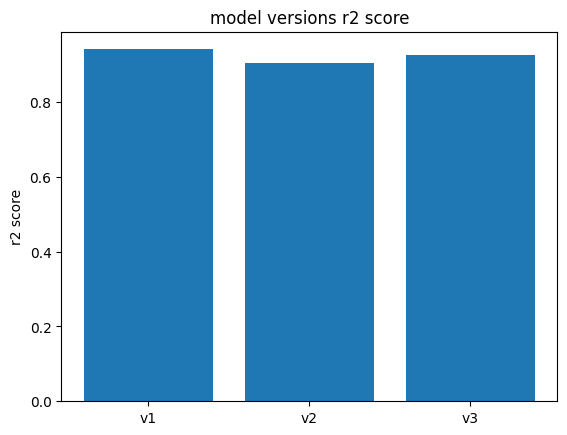

In [16]:
# plot model versions performance comparison
versions = list(manager.metadata['versions'].keys())
scores = [manager.metadata['versions'][v]['metrics']['r2'] for v in versions]

plt.bar(versions, scores)
plt.title('model versions r2 score')
plt.ylabel('r2 score')
plt.show()